# MCMC Correctness Check

In this notebook we will verify the correctness of the MCMC results for a single exposure fit.

In [36]:
from fitting_engine import FittingEngine
import numpy as np
import matplotlib.pyplot as plt

engine = FittingEngine(verbose=True)

Define properties of the test data.

In [37]:
# slicing properties
n_points = 30
true_y_err_std = 0.05
x_length = 3

# material properties
order = 0.0
sigma_phi = 5
mu = 5

# sample parameters
true_t_exposure_1 = 1_000

Generate test data from the given parameters.

In [38]:
# generate measurement sample data
x_data = np.linspace(0, x_length, n_points)
y_data = engine.models.expo(x_data, order, sigma_phi, mu, true_t_exposure_1)
# add random perturbation
perturbation = np.random.normal(loc=0.0, scale=true_y_err_std, size=n_points)
y_data += perturbation

Plot generated test data and true curve.

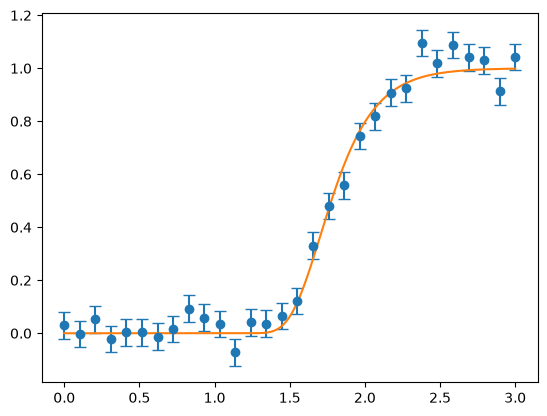

In [39]:
plt.errorbar(x_data, y_data, yerr=true_y_err_std, fmt='o', capsize=4)
x_curve_plot = np.linspace(0, x_length, 500)
y_curve_plot = engine.models.expo(x_curve_plot, order, sigma_phi, mu,
    true_t_exposure_1)
plt.plot(x_curve_plot, y_curve_plot)
plt.show()

Perform the MCMC fit.

In [40]:
# known parameters
known_params = {"order": order, "sigma_phi": sigma_phi, "mu": mu}

# known parameter distributions
known_params_distribution = {
    ("order",): (order, 0.0),
    ("sigma_phi",): (sigma_phi, 0.0),
    ("mu",): (mu, 0.0)
}

# bounds for uniform priors
free_params_bounds = {"t_exposure_1": (0, 1000_000)}

y_err_std = np.full(x_data.shape, true_y_err_std)

# get initial guess
initial_guess = engine.get_initial_guess(x_data, y_data,
    engine.models.expo, known_params, bounds=free_params_bounds,
    y_err_std=y_err_std)

# bayesian fit
fit_result = engine.bayesian_fit(100_000, 20_000, x_data, y_data, y_err_std,
    engine.models.expo, initial_guess, free_params_bounds,
    known_params_distribution)

success = fit_result.success
samples = fit_result.marginal_samples["t_exposure_1"]

print(success)

You must install the tqdm library to use progress indicators with emcee
You must install the tqdm library to use progress indicators with emcee


True


Plot probability distribution of `t_exposure_1`.

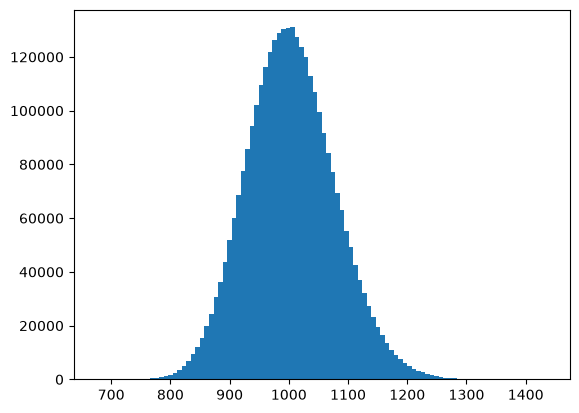

In [41]:
plt.hist(samples, bins=100)
plt.show()

Now we will calculate the true distribution of `t_exposure_1` by evaluating Bayes theorem on a grid to then compare the result with MCMC.

Bayes theorem is
$$
p(t \mid D) \propto p(D \mid t) \, p(t),
$$
the probability of distribution of $t$ given the observed data $D$ is proportional to $p(D \mid t)$, the probability of getting such data assuming $t$ as the true value and $p(t)$, the prior information about $t$.

Since we assume no prior knowledge about $t$, $p(t)$ can be discarded. The remaining step is to find $p(D \mid t)$. It is given by 
$$
p(D\mid t) = \prod_{i=0}^{n} \mathcal{N} \left(y_i; f(x_i; t), \sigma \right)
= \prod_{i=0}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \exp \left(-\frac{(y_i-f(x_i; t))^2}{2\sigma^2}\right)
\propto \exp \left(-\frac{1}{2\sigma^2} \sum_{i=0}^{n}(y_i-f(x_i; t))^2\right).
$$

In [42]:
def p_data_given_t(t_exposure):
    f_data = engine.models.expo(x_data, order, sigma_phi, mu, t_exposure)
    return np.exp(-1/(2*true_y_err_std**2) * np.sum((y_data - f_data)**2))

bounds_t_exposure = (0, 20_000)
num_eval_points = 100_000
eval_grid = np.linspace(bounds_t_exposure[0], bounds_t_exposure[1],
    num_eval_points)

p_grid = []
for t_val in eval_grid:
    p_grid.append(p_data_given_t(t_val))

norm = np.trapezoid(p_grid, eval_grid)
p_grid_normalized = p_grid / norm

Now we can overlay the MCMC result with the Bayesian grid inference to check the reliability of MCMC.

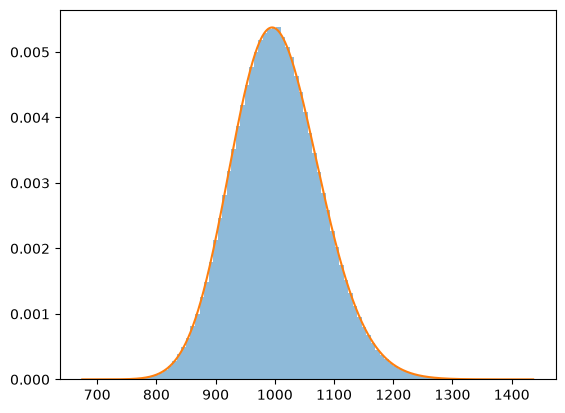

In [43]:
min_s = min(samples)
max_s = max(samples)

mask = (eval_grid >= min_s) & (eval_grid <= max_s)

eval_grid_window = eval_grid[mask]
p_grid_normalized_window = p_grid_normalized[mask]

plt.hist(samples, bins=100, density=True, alpha=0.5)
plt.plot(eval_grid_window, p_grid_normalized_window)
plt.show()

The exact grid inference and the MCMC samples match perfectly, confirming the correctness of the MCMC method. Also, both are very similar to the Monte Carlo experiment performed in `1_explore_errors.ipynb`, which uses the same parameters. This is also a good confirmation, however these two probability distirbutions of the exposure time do not describe exactly the same thing mathematically.